# 📊 매거진형 에디토리얼 저성과 Cutoff 분석

반복 전시되는 매거진형 에디토리얼의 **Full Engagement 분포를 분석하고 저성과 Cutoff 후보를 검토**합니다.

- 분석 기간: 2026년 W01~W20
- 분석 단위: 주차 × 에디토리얼
- 핵심 지표: 일평균 Full Engagement
- 분석 흐름: 전시일수 보정 → Percentile → Histogram → CDF → KDE → 3-Out 대상 확인

> 공개용 Notebook에서는 실제 회사 데이터 대신 합성 `sample_engagement.csv`를 사용합니다.


In [1]:
### 라이브러리 호출
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime, timedelta
from pathlib import Path
from scipy.stats import gaussian_kde

print('라이브러리 호출 완료')


라이브러리 호출 완료


## 1. 주차 기준 생성

2026-01-01을 W01 시작일로 두고 7일 단위 주차 테이블을 생성합니다.


In [2]:
### 주차 기준 생성
start_date = datetime(2026, 1, 1)
end_date = datetime(2026, 12, 30)

weeks = []
current_date = start_date

for week_num in range(1, 53):
    week_label = f'26Y W{str(week_num).zfill(2)}'
    end_of_week = current_date + timedelta(days=6)

    weeks.append({
        'Week': week_label,
        'Week Start Date': current_date.strftime('%Y-%m-%d'),
        'Week End Date': end_of_week.strftime('%Y-%m-%d')
    })

    current_date = end_of_week + timedelta(days=1)

df_weeks = pd.DataFrame(weeks)

df_weeks['Week Start Date'] = pd.to_datetime(
    df_weeks['Week Start Date']
).dt.normalize()

df_weeks['Week End Date'] = pd.to_datetime(
    df_weeks['Week End Date']
).dt.normalize()

display(df_weeks.head(3))


,Week,Week Start Date,Week End Date
0,26Y W01,2026-01-01,2026-01-07
1,26Y W02,2026-01-08,2026-01-14
2,26Y W03,2026-01-15,2026-01-21


## 2. 데이터 호출

실제 분석에서는 주차별 에디토리얼 정보와 Engagement 집계 파일을 결합했습니다.  
공개용 Notebook에서는 동일 분석 컬럼을 포함한 합성 데이터를 사용합니다.


In [3]:
### 데이터 호출
data_path = Path('../sample_data/sample_engagement.csv')

if not data_path.exists():
    data_path = Path('/mnt/data/sample_engagement.csv')

df = pd.read_csv(data_path)

print(f'데이터 크기: {df.shape[0]:,}행 × {df.shape[1]}열')
display(df.head(3))


데이터 크기: 401행 × 9열


,Week,Component Key,Component Title,Display Type,Category,Price Type,Life Start Date,Life End Date,Full Engagement
0,26Y W01,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-02-15,8134
1,26Y W02,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-02-15,9506
2,26Y W03,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-02-15,26474


In [4]:
### 날짜형 변환
df['Life Start Date'] = pd.to_datetime(
    df['Life Start Date']
).dt.normalize()

df['Life End Date'] = pd.to_datetime(
    df['Life End Date']
).dt.normalize()

display(
    df[
        ['Week', 'Component Key', 'Life Start Date', 'Life End Date']
    ].head(3)
)


,Week,Component Key,Life Start Date,Life End Date
0,26Y W01,editorial_001,2026-01-01,2026-02-15
1,26Y W02,editorial_001,2026-01-01,2026-02-15
2,26Y W03,editorial_001,2026-01-01,2026-02-15


## 3. 실제 전시일수 및 일평균 Full Engagement 계산

에디토리얼별 운영 기간과 각 주차 범위를 비교해 실제 전시일수를 계산한 뒤,  
주차별 Full Engagement를 실제 전시일수로 나누어 일평균 성과를 산출합니다.


In [5]:
### 주차 정보 결합
df = df.merge(
    df_weeks,
    on='Week',
    how='left'
)

display(
    df[
        ['Week', 'Component Key', 'Week Start Date', 'Week End Date']
    ].head(3)
)


,Week,Component Key,Week Start Date,Week End Date
0,26Y W01,editorial_001,2026-01-01,2026-01-07
1,26Y W02,editorial_001,2026-01-08,2026-01-14
2,26Y W03,editorial_001,2026-01-15,2026-01-21


In [6]:
### 실제 전시일수 계산
df['Actual Start Date'] = df[
    ['Life Start Date', 'Week Start Date']
].max(axis=1)

df['Actual End Date'] = df[
    ['Life End Date', 'Week End Date']
].min(axis=1)

df = df[
    [
        'Week',
        'Component Key',
        'Component Title',
        'Display Type',
        'Category',
        'Price Type',
        'Actual Start Date',
        'Actual End Date',
        'Full Engagement'
    ]
]

df['Display Days'] = (
    df['Actual End Date'] - df['Actual Start Date']
).dt.days + 1

df['Full Engagement(Avg.)'] = (
    df['Full Engagement'] / df['Display Days']
)

display(df.head())


,Week,Component Key,Component Title,Display Type,Category,Price Type,Actual Start Date,Actual End Date,Full Engagement,Display Days,Full Engagement(Avg.)
0,26Y W01,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-01-07,8134,7,1162.0
1,26Y W02,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-08,2026-01-14,9506,7,1358.0
2,26Y W03,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-15,2026-01-21,26474,7,3782.0
3,26Y W04,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-22,2026-01-28,35322,7,5046.0
4,26Y W05,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-29,2026-02-04,21581,7,3083.0


## 4. Percentile Analysis

전체 에디토리얼의 일평균 Full Engagement를 기준으로 주요 Percentile을 계산합니다.


In [7]:
### Percentile 계산
fe = df['Full Engagement(Avg.)']

percentiles = {
    'P10': np.percentile(fe, 10),
    'P25': np.percentile(fe, 25),
    'Median(P50)': np.percentile(fe, 50),
    'P75': np.percentile(fe, 75),
    'P90': np.percentile(fe, 90)
}

percentile_df = pd.DataFrame({
    'Percentile': percentiles.keys(),
    'Full Engagement': percentiles.values()
})

percentile_df['Full Engagement'] = (
    percentile_df['Full Engagement']
    .round(0)
    .astype(int)
)

display(percentile_df)


,Percentile,Full Engagement
0,P10,792
1,P25,1965
2,Median(P50),3117
3,P75,5168
4,P90,9271


## 5. Histogram

전체 일평균 Full Engagement 분포를 확인합니다.


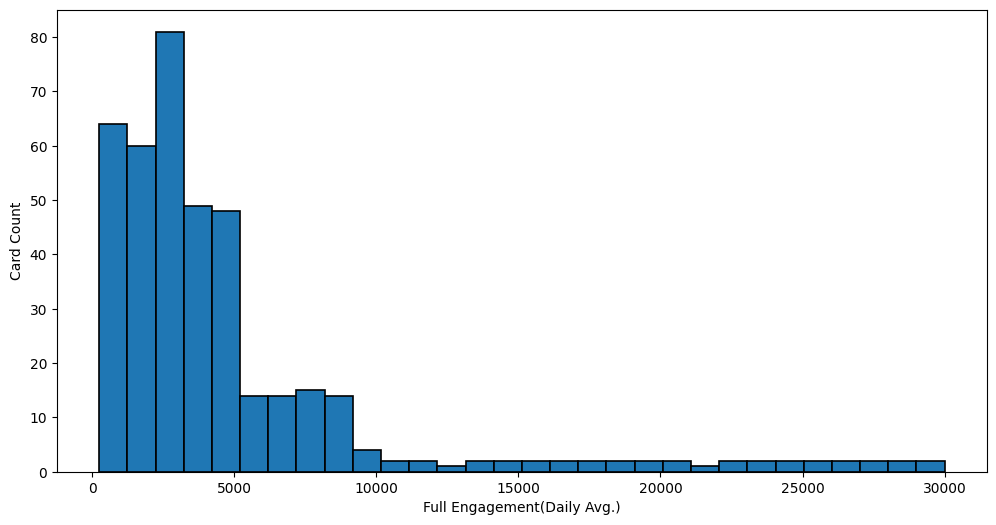

최소값: 250 / 중앙값: 3,117 / 최대값: 30,000


In [8]:
### Histogram
plt.figure(figsize=(12, 6))

plt.hist(
    fe,
    bins=30,
    edgecolor='black',
    linewidth=1.2
)

plt.xlabel('Full Engagement(Daily Avg.)')
plt.ylabel('Card Count')
plt.show()

print(
    f'최소값: {fe.min():,.0f} / '
    f'중앙값: {fe.median():,.0f} / '
    f'최대값: {fe.max():,.0f}'
)


## 6. CDF Plot

특정 Full Engagement 값 이하의 에디토리얼이 전체에서 어느 정도 비중을 차지하는지 확인합니다.


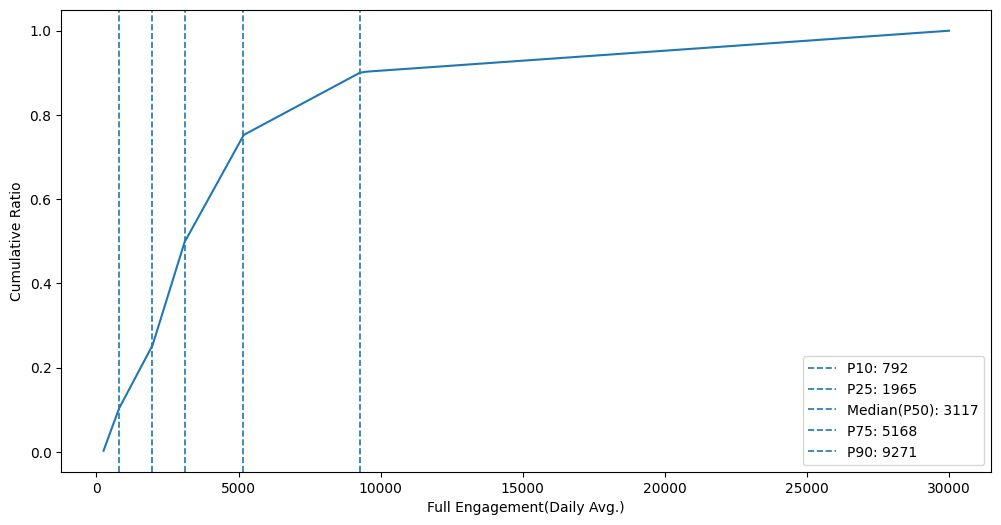

In [9]:
### CDF Plot
x = np.sort(fe)
y = np.arange(1, len(x) + 1) / len(x)

plt.figure(figsize=(12, 6))
plt.plot(x, y, linewidth=1.5)

for label, value in percentiles.items():
    plt.axvline(
        value,
        linestyle='--',
        linewidth=1.2,
        label=f'{label}: {value:.0f}'
    )

plt.xlabel('Full Engagement(Daily Avg.)')
plt.ylabel('Cumulative Ratio')
plt.legend()
plt.show()


## 7. KDE Plot

에디토리얼 성과가 주로 분포하는 구간과 주요 Percentile 위치를 함께 확인합니다.


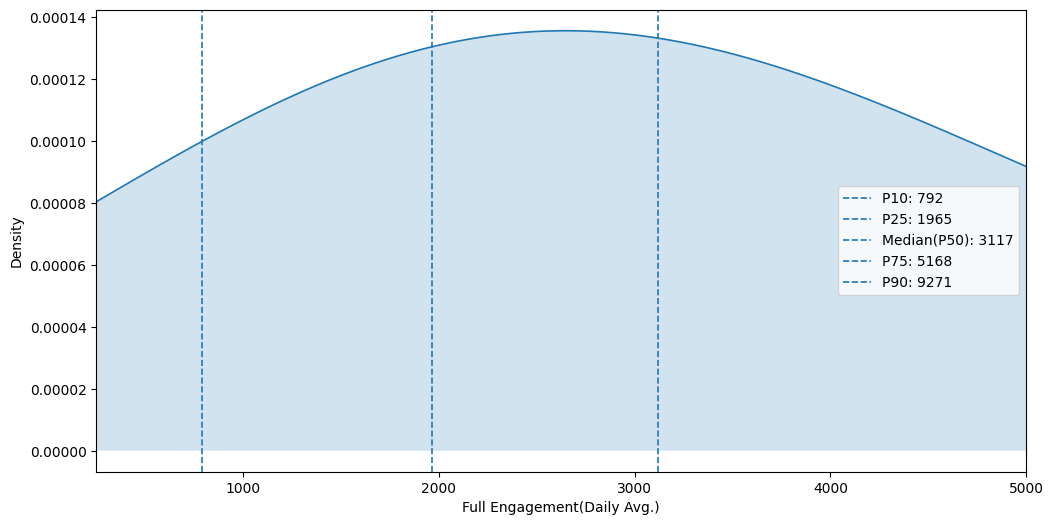

In [10]:
### KDE Plot
kde = gaussian_kde(fe)
x_kde = np.linspace(fe.min(), 5000, 500)
y_kde = kde(x_kde)

plt.figure(figsize=(12, 6))
plt.plot(x_kde, y_kde, linewidth=1.2)
plt.fill_between(x_kde, y_kde, alpha=0.2)

for label, value in percentiles.items():
    plt.axvline(
        value,
        linestyle='--',
        linewidth=1.2,
        label=f'{label}: {value:.0f}'
    )

plt.xlim(fe.min(), 5000)
plt.xlabel('Full Engagement(Daily Avg.)')
plt.ylabel('Density')
plt.legend()
plt.show()


## 8. 3-Out 대상 확인


In [11]:
### 저성과 Cutoff 이하 데이터 추출
cutoff = percentiles['P25']

df_cutoff = df[
    df['Full Engagement(Avg.)'] <= cutoff
]

display(df_cutoff.head())


,Week,Component Key,Component Title,Display Type,Category,Price Type,Actual Start Date,Actual End Date,Full Engagement,Display Days,Full Engagement(Avg.)
0,26Y W01,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-01,2026-01-07,8134,7,1162.0
1,26Y W02,editorial_001,Editorial 001,Basic Card,Game,Free,2026-01-08,2026-01-14,9506,7,1358.0
7,26Y W04,editorial_002,Editorial 002,App List,App,Paid,2026-01-23,2026-01-28,3210,6,535.0
8,26Y W05,editorial_002,Editorial 002,App List,App,Paid,2026-01-29,2026-02-04,3171,7,453.0
14,26Y W07,editorial_003,Editorial 003,Grid Content,Theme,Free,2026-02-14,2026-02-18,5520,5,1104.0


In [12]:
### 에디토리얼별 저성과 누적 횟수 확인
out_count = (
    df_cutoff
    .groupby('Component Key')
    .size()
    .reset_index(name='Out Count')
    .sort_values(
        'Out Count',
        ascending=False
    )
)

display(out_count.head(10))


,Component Key,Out Count
0,editorial_001,2
1,editorial_002,2
2,editorial_003,2
3,editorial_004,2
4,editorial_005,2
5,editorial_006,2
6,editorial_007,2
7,editorial_008,2
8,editorial_009,2
9,editorial_010,2


In [13]:
### 3-Out 대상 에디토리얼 추출
three_out = out_count[
    out_count['Out Count'] >= 3
]

three_out


,Component Key,Out Count


## 9. 분석 결과

- P10: **792**
- P25: **1,965**
- Median(P50): **3,117**
- P75: **5,168**
- P90: **9,271**
- P25 이하 구간을 저성과 Cutoff 후보로 검토
- 사전에 제안했던 Full Engagement 2,000 이하 기준과 실제 P25가 근접한 수준인지 확인
